In [1]:
import sys, os
sys.path.append(os.path.abspath(".."))

In [2]:
import torch

print("Torch:", torch.__version__)
print("Torch CUDA:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

Torch: 2.6.0+cu124
Torch CUDA: 12.4
CUDA available: True


In [3]:
import torch

from utils.seed import set_seed

SEED = 42
set_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 50)
print(f"Seed   : {SEED}")
print(f"Device : {DEVICE}")

if torch.cuda.is_available():
    print(f"GPU    : {torch.cuda.get_device_name(0)}")

print("=" * 50)

Seed set to: 42
Seed   : 42
Device : cuda
GPU    : Tesla T4


In [4]:
from benchmarks.benchmark_factory import build_benchmark
from models.model_factory import build_model
from evaluation.evaluator_factory import build_evaluator
from strategies.strategy_factory import build_strategy
from experiments.runner import run_continual_experiment

from evaluation.plots import (
    plot_result_matrix,
    plot_accuracy_by_experience,
    plot_three_protocols,
)

In [5]:
benchmark_name="split_mnist"
model_name="avalanche_simplemlp"
strategy_name = "naive"
output_dir=f"../outputs/{benchmark_name}/{strategy_name}/{model_name}/"


benchmark = build_benchmark(
    benchmark_name=benchmark_name,
    n_experiences=5,
    seed=1234,
)

model = build_model(
    model_name=model_name,
    num_classes=10,
).to(DEVICE)

evaluator = build_evaluator(
    log_dir=output_dir+"logs",
    use_interactive=False,
    use_text=False,
    use_tensorboard=True,
)

strategy = build_strategy(
    strategy_name=strategy_name,
    model=model,
    evaluator=evaluator,
    optimizer_name="sgd",
    lr=0.01,
    momentum=0.9,
    train_mb_size=64,
    eval_mb_size=128,
    train_epochs=1,
    device=DEVICE,
)

result = run_continual_experiment(
    strategy=strategy,
    benchmark=benchmark,
    output_dir=output_dir,
)

R = result["R"]
metrics = result["metrics"]

Training experience 1/5
Evaluating on full test stream
Training experience 2/5
Evaluating on full test stream
Training experience 3/5
Evaluating on full test stream
Training experience 4/5
Evaluating on full test stream
Training experience 5/5
Evaluating on full test stream


In [6]:
def print_metrics_table(title, metrics):
    print("\n" + "=" * 80)
    print(f"{title:^80}")
    print("=" * 80)

    print(f"| {'Metric':<40} | {'Value':>20} |")
    print("-" * 65)

    for key, value in metrics.items():
        if isinstance(value, float):
            value = f"{value:.4f}" if value == value else "N/A"

        print(f"| {key:<40} | {str(value):>20} |")

    print("=" * 80)


                           CONTINUAL LEARNING METRICS                           
| Metric                                   |                Value |
-----------------------------------------------------------------
| A Metric                                 |               0.1994 |
| ACC Metric                               |               0.3315 |
| Model Size                               |               407050 |
| BWT (Backward Transfer)                  |              -0.9927 |
| BWT+ (Positive Backward Transfer)        |               0.0000 |
| FWT (Forward Transfer)                   |               0.0000 |
| Forgetting                               |               0.9927 |
| REM (Remembering)                        |               0.0073 |
| MS (Memory Score)                        |               1.0000 |
| SSS (Sample Storage Score)               |               1.0000 |
| CE (Compute Efficiency)                  |               1.0000 |
| Total Train Time                  

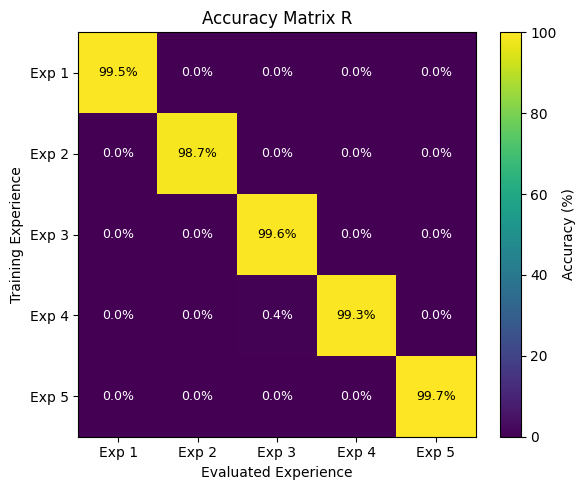

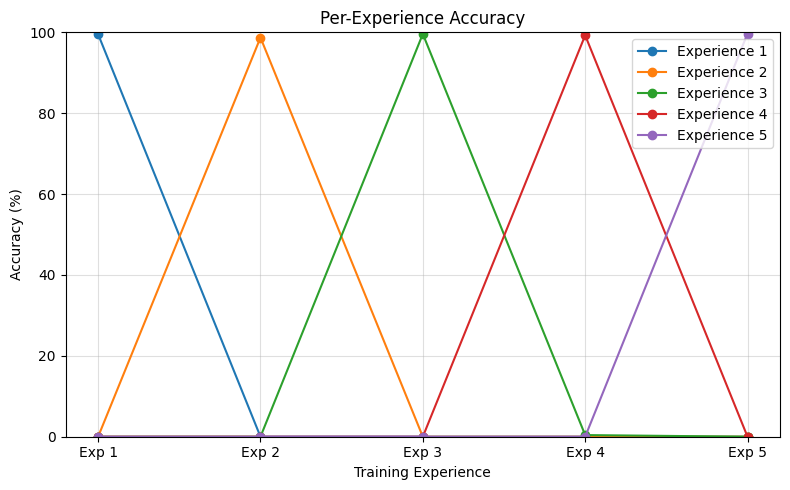

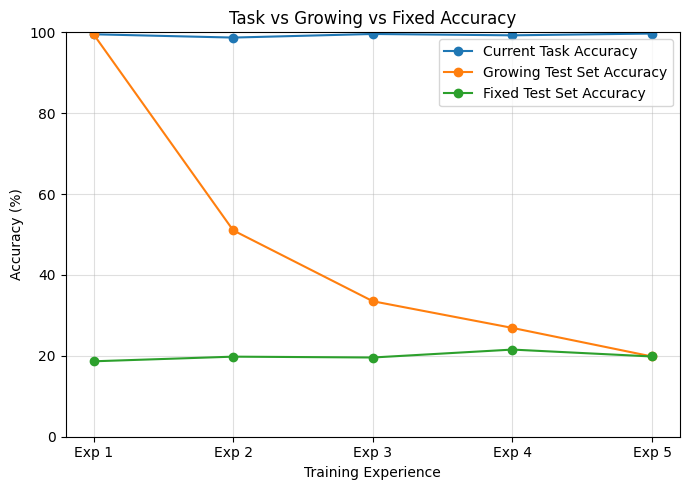

In [7]:
 print_metrics_table(
    title="CONTINUAL LEARNING METRICS",
    metrics=metrics,
)

plot_result_matrix(
    R,
    title="Accuracy Matrix R",
)

plot_accuracy_by_experience(R)

plot_three_protocols(
    task_accs=result["task_accs"],
    growing_accs=result["growing_accs"],
    fixed_accs=result["fixed_accs"],
)